# Лекция 2. Как ставить задачу модели — и проверять, что она её решила

*Искусственный интеллект в инженерном образовании · НИУ ВШЭ · 2026/27*

В прошлый раз мы поняли, что модель — это угадайка следующего токена, и научились с ней разговаривать.
Сегодня вопрос практичнее: **как заставить её делать то, что нужно, — и не врать себе, что получилось?**

У нас две истории на всю пару. Первая — про Сашу, который пошёл за покупками, и модель, которая не может посчитать
его чек. Вторая — про сто заявок в сервисную компанию (из ЛР1, так что заодно увидите данные): на старте модель угадывает их категорию так себе,
и каждую новую технику мы будем проверять на них. К концу пары посмотрим, как далеко удалось забраться.

В программе:
1. промпт — это техническое задание, а не просьба;
2. примеры, которые решают;
3. думать или не думать — и сколько это стоит;
4. JSON, который не ломается никогда;
5. почему цифрам на ста примерах нельзя верить на слово;
6. модель, которая сама улучшает свой промпт;
7. промпты для агентов и промпт как код.

## 0. Подготовка

In [1]:
import sys, os, math, time, json, re, random
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install langchain==1.4.6 langchain-ollama==1.1.0 pydantic==2.14.1
    !curl -fsSL https://ollama.com/install.sh | sh
    import subprocess
    subprocess.Popen(["ollama", "serve"], env=dict(os.environ, OLLAMA_KEEP_ALIVE="-1"),
                     stdout=open("ollama.log", "w"), stderr=subprocess.STDOUT)
    time.sleep(5)

In [2]:
MODEL = os.environ.get("LECTURE_MODEL", "qwen3.5:4b")
OLLAMA = "http://localhost:11434"
if IN_COLAB:
    !ollama pull {MODEL}

import html, requests, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import HTML, display
from langchain_ollama import ChatOllama
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

GREEN, ORANGE, RED, BLUE, GREY = "#2a7f62", "#e07a3f", "#c0392b", "#3d6fb6", "#7a8580"
pd.set_option("display.max_colwidth", 120)

def ollama(path, **body):
    r = requests.post(f"{OLLAMA}/api/{path}", json={"model": MODEL, "stream": False, **body}, timeout=1800)
    r.raise_for_status()
    return r.json()

llm = ChatOllama(model=MODEL, temperature=0, reasoning=False)
print(llm.invoke("Готов к лекции? Одним словом.").content)

Да, готов! 🎤

Чем будем заниматься:
*   **Тема** для обсуждения или разбора?
*   Нужен ли **план** (конспект) по конкретной теме?
*   Или мы просто **поговорим** на интересную вам тему?

Жду вашего сигнала!


Данные — заявки из ЛР1 (файл `LR1_train.csv`; в Colab загрузите его или весь `lr1_student.zip`). Перемешаем и разделим на три части: **dev** — на нём подбираем
промпты, **test** — его не трогаем до самого конца, **pool** — запас примеров для few-shot.

In [3]:
TRAIN = os.environ.get("LR1_TRAIN", "data/LR1_train.csv")
if IN_COLAB and not os.path.exists(TRAIN):
    from google.colab import files
    import zipfile, glob
    TRAIN = next(iter(files.upload()))             # LR1_train.csv или lr1_student.zip из материалов ЛР1
    if TRAIN.endswith(".zip"):
        zipfile.ZipFile(TRAIN).extractall("lr1_upload")
        TRAIN = glob.glob("lr1_upload/**/LR1_train.csv", recursive=True)[0]
data = pd.read_csv(TRAIN, dtype=str).fillna("").sample(frac=1, random_state=0).reset_index(drop=True)
DEV, TEST, POOL = data.iloc[:100], data.iloc[100:250], data.iloc[250:]
CATS = ["ремонт", "техобслуживание", "монтаж", "демонтаж", "гарантийный случай", "консультация", "запчасти"]
print(f"dev {len(DEV)}, test {len(TEST)}, pool {len(POOL)}")
DEV.category.value_counts()

dev 100, test 150, pool 50


category
ремонт                28
консультация          17
техобслуживание       15
запчасти              12
демонтаж              10
монтаж                 9
гарантийный случай     9
Name: count, dtype: int64

In [4]:
def to_label(answer, cats=CATS):
    a = answer.lower().replace("ё", "е")
    for c in sorted(cats, key=len, reverse=True):
        if c.replace("ё", "е") in a:
            return c
    return None          # модель ответила что-то не из списка

def evaluate(chain, df, label=None):
    answers = [a.strip() for a in chain.batch([{"text": t} for t in df.text], config={"max_concurrency": 4})]
    evaluate.last = answers
    preds = [a if a in CATS else to_label(a) for a in answers]
    acc = float(np.mean([p == g for p, g in zip(preds, df.category)]))
    bad = float(np.mean([p is None for p in preds]))
    if label:
        ladder[label] = acc
    return acc, bad, preds

ladder = {}          # «лестница качества» — каждую технику сюда, итог в конце пары

## Холодное начало: Саша идёт за покупками

> Саша купил 3 рубашки по 1 200 рублей и 2 пары джинсов по 3 500 рублей. На кассе ему дали скидку 15% на всю покупку.
> Сколько Саша заплатил?

Посчитаем в уме: $(3 \cdot 1200 + 2 \cdot 3500) \cdot 0{,}85 = 10\,600 \cdot 0{,}85 = 9\,010$.

🗳️ **Ваш прогноз.** Справится ли модель, если попросить её ответить сразу, одним числом?

In [5]:
SASHA = ("Саша купил 3 рубашки по 1 200 рублей и 2 пары джинсов по 3 500 рублей. На кассе ему дали скидку 15% "
         "на всю покупку. Сколько Саша заплатил?")

def chat(question, think=False, **opts):
    d = ollama("chat", messages=[{"role": "user", "content": question}], think=think,
               options={"temperature": 0, "num_predict": 4000, **opts})
    return d["message"]["content"].strip(), d.get("eval_count", 0)

ans, n = chat(SASHA + " Ответь только числом.")
print(f"сразу:          {ans!r:<20} ({n} токенов)")
ans, n = chat(SASHA + " Решай шаг за шагом, в конце напиши «Ответ: N».")
print(f"шаг за шагом:   …{ans[-60:]!r} ({n} токенов)")
ans, n = chat(SASHA + " Ответь только числом.", think=True)
print(f"режим «думай»:  {ans!r:<20} ({n} токенов)")

сразу:          '4680'               (4 токенов)


шаг за шагом:   …'\\% = 85\\%$).\n$10600 \\times 0,85 = 9010$ рублей.\n\nОтвет: 9010' (414 токенов)


режим «думай»:  '9010'               (976 токенов)


Выходит, достаточно сказать «думай» — и модель умнеет? Не так быстро. Когда мы готовили ЛР3, Qwen3.5-9B (старшая сестра нашей модели) в режиме
рассуждений на сложных задачах сжигала **все 16 тысяч токенов** бюджета на размышления — и так и не написала ни строчки
кода. Думать дорого, и не всегда окупается. Где граница — разберёмся в разделе 3.

А теперь вторая история. Сто заявок в сервисную компанию, семь категорий: ремонт, ТО, монтаж и так далее.
Спросим модель в лоб — как спросил бы любой человек.

In [6]:
def cards(df, n=3):
    out = "".join(f'<div style="border-left:4px solid {BLUE};background:#f3f6fb;padding:8px 12px;margin:6px 0;'
                  f'border-radius:4px"><small style="color:{GREY}">{r.channel} · правильно: <b>{r.category}</b></small>'
                  f'<br>{html.escape(r.text)}</div>' for r in df.head(n).itertuples())
    display(HTML(out))

cards(DEV)

In [7]:
NAIVE = "Определи категорию обращения: " + ", ".join(CATS) + "."
naive = ChatPromptTemplate.from_messages([("human", NAIVE + "\n\n{text}")]) | llm | StrOutputParser()

acc, bad, preds_naive = evaluate(naive, DEV, "0. спросили в лоб")
print(f"точность {acc:.0%}, ответов не из списка {bad:.0%}")

точность 47%, ответов не из списка 0%


Что модель вообще отвечает? Заглянем в пару ответов.

In [8]:
for a in evaluate.last[:3]:
    print("─" * 80 + "\n" + a[:400] + ("…" if len(a) > 400 else ""))
lens = [len(a) for a in evaluate.last]
print(f"\nсредняя длина ответа: {np.mean(lens):.0f} символов — а нам нужно одно слово")
multi = np.mean([sum(c in a.lower() for c in CATS) > 1 for a in evaluate.last])
print(f"ответов, где названо больше одной категории: {multi:.0%}")

────────────────────────────────────────────────────────────────────────────────
Основываясь на тексте обращения, можно выделить следующие ключевые моменты:
1.  **Проблема:** У чиллера Trane возникла неисправность (сильный шум компрессора).
2.  **Действие клиента:** Клиент готов оплатить услуги до 2000 тыс. рублей и просит направить специалиста для **диагностики**.
3.  **Цель письма:** Согласовать визит мастера для выявления причины поломки.

Хотя в тексте упоминаются слова «р…
────────────────────────────────────────────────────────────────────────────────
На основе описанной ситуации (авария в котле Вайлант, падение давления, замерзание здания) правильная категория обращения — **ремонт**.

**Обоснование:**
*   **Ремонт** подразумевает устранение неисправностей и восстановление работоспособности оборудования после сбоев или аварийных ситуаций. Поскольку у клиента сломался котел (постоянно падает давление), это классический случай ремонта.
*   *Техоб…
──────────────────────────────────

Модель пишет сочинение — с обоснованием, оговорками и «хотя, с другой стороны…». И часто называет в нём сразу
несколько категорий. Какую из них считать ответом? Наш разборщик берёт первую подходящую — и нередко промахивается.
Так что в этой цифре смешаны две беды: модель не поняла задачу **и** мы не поняли модель.

Вот наша стартовая ступенька. К концу пары посмотрим, сколько удастся из неё выжать — **без смены модели и без
обучения**, только правильной постановкой задачи.

## 1. Промпт — это ТЗ, а не просьба

Начнём с самого дешёвого: одна фраза в конец промпта.

🗳️ **Ваш прогноз.** Сколько пунктов точности даст фраза «Ответь только названием категории»?

In [9]:
SIMPLE = NAIVE + " Ответь только названием категории."
simple = ChatPromptTemplate.from_messages([("human", SIMPLE + "\n\n{text}")]) | llm | StrOutputParser()
acc, bad, _ = evaluate(simple, DEV, "1. «ответь только названием»")
print(f"точность {acc:.0%} (было {ladder['0. спросили в лоб']:.0%})")

точность 88% (было 47%)


Бам! Одна фраза — и огромный прирост. Значительная часть «ошибок» в лоб была вовсе не ошибками понимания,
а ошибками **формата**: модель знала ответ, но утопила его в сочинении. Формат ответа — первое, что нужно
зафиксировать в любом промпте.

Но модель всё ещё путается в границах. Представьте, что вы наняли стажёра и сказали ему: «Определи категорию обращения». Что он сделает? Будет гадать.
Что такое «гарантийный случай», если клиент сломал кондиционер, который на гарантии? Это ремонт или гарантия?
А если человек спрашивает, сколько стоит чистка, — это консультация или ТО?

Нормальный стажёр получил бы **техническое задание**. Модель — тоже.

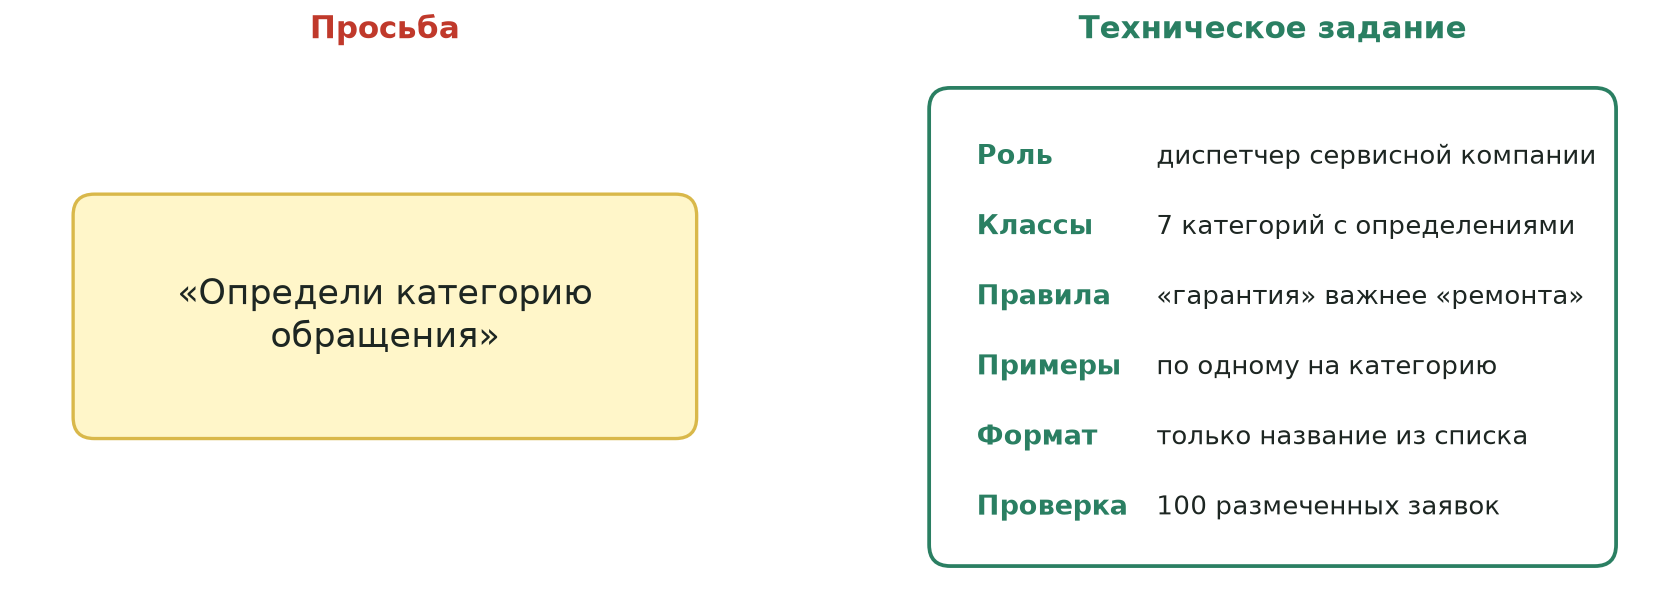

*Один и тот же вопрос — как просьба и как ТЗ*

In [10]:
SPEC = '''Ты диспетчер сервисной компании, которая ремонтирует и обслуживает инженерное оборудование.
Определи категорию обращения клиента.

Категории:
- ремонт — что-то сломалось, нужно починить, о гарантии речи нет;
- гарантийный случай — неисправность, и клиент ссылается на гарантию (важнее, чем «ремонт»);
- техобслуживание — плановое ТО, чистка, профилактика;
- монтаж — установить и подключить новое оборудование;
- демонтаж — снять, демонтировать старое;
- консультация — клиент задаёт вопрос и не просит приехать;
- запчасти — клиент хочет купить деталь.

Ответь только названием категории из списка, без пояснений.'''

spec = ChatPromptTemplate.from_messages([("system", SPEC), ("human", "{text}")]) | llm | StrOutputParser()
acc, bad, preds_spec = evaluate(spec, DEV, "2. написали ТЗ")
print(f"точность {acc:.0%}, ответов не из списка {bad:.0%}")
print(f"формат ответа дал {100 * (ladder['1. «ответь только названием»'] - ladder['0. спросили в лоб']):+.0f} п.п., "
      f"определения и роль — ещё {100 * (acc - ladder['1. «ответь только названием»']):+.0f} п.п.")

точность 97%, ответов не из списка 0%
формат ответа дал +41 п.п., определения и роль — ещё +9 п.п.


Где модель всё ещё путается? Посмотрим на **матрицу ошибок**: по строкам — правильная категория, по столбцам —
что ответила модель. Всё, что не на диагонали, — ошибки.

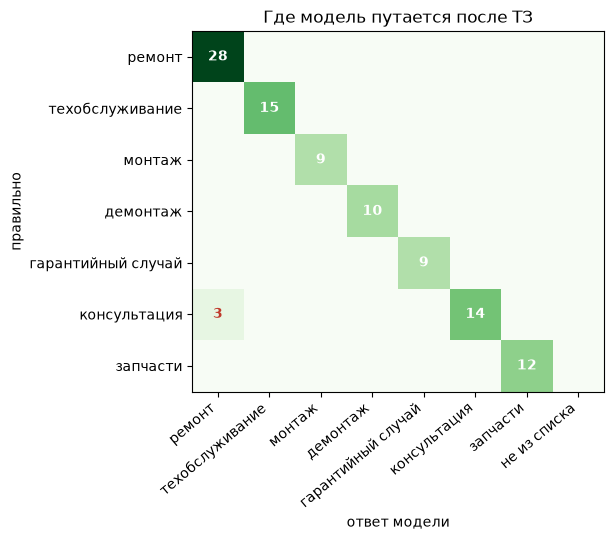

In [11]:
def confusion(preds, gold, title):
    names = CATS + ["не из списка"]
    m = np.zeros((len(CATS), len(names)), dtype=int)
    for p, g in zip(preds, gold):
        m[CATS.index(g), names.index(p) if p in CATS else len(CATS)] += 1
    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    ax.imshow(m, cmap="Greens")
    ax.set_xticks(range(len(names)), names, rotation=40, ha="right"); ax.set_yticks(range(len(CATS)), CATS)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            if m[i, j]:
                ax.text(j, i, m[i, j], ha="center", va="center", color="white" if i == j else RED, weight="bold")
    ax.set_xlabel("ответ модели"); ax.set_ylabel("правильно"); ax.set_title(title)
    plt.tight_layout(); plt.show()

confusion(preds_spec, DEV.category, "Где модель путается после ТЗ")

Ошибок осталось немного, и они не случайны: сидят на границах, которые размыты даже для человека, — консультация
или ремонт, гарантия или нет. Это и есть подсказка, что делать дальше. Словами границу объяснить трудно.
А что если **показать**?

## 2. Примеры решают

Few-shot — старейший трюк в мире LLM (GPT-3, 2020): вместо объяснений показываем модели несколько решённых примеров.
В LangChain для этого есть готовый шаблон.

🗳️ **Ваш прогноз.** Сколько примеров нужно, чтобы стало заметно лучше? Один? Три? Восемь?

In [12]:
from langchain_core.prompts import FewShotChatMessagePromptTemplate

def with_examples(examples, system=SPEC):
    shots = FewShotChatMessagePromptTemplate(
        example_prompt=ChatPromptTemplate.from_messages([("human", "{text}"), ("ai", "{category}")]),
        examples=[{"text": r.text, "category": r.category} for r in examples.itertuples()])
    return ChatPromptTemplate.from_messages([("system", system), shots, ("human", "{text}")]) | llm | StrOutputParser()

few = {}
for k in [1, 3, 8]:
    few[k], _, _ = evaluate(with_examples(POOL.sample(k, random_state=k)), DEV)
    print(f"{k} случайных примеров: {few[k]:.0%}")

per_class = POOL.groupby("category").head(1)          # по одному примеру на категорию
acc, _, preds_few = evaluate(with_examples(per_class), DEV, "3. по примеру на категорию")
print(f"по одному на каждую из 7 категорий: {acc:.0%}")

1 случайных примеров: 95%


3 случайных примеров: 96%


8 случайных примеров: 95%


по одному на каждую из 7 категорий: 96%


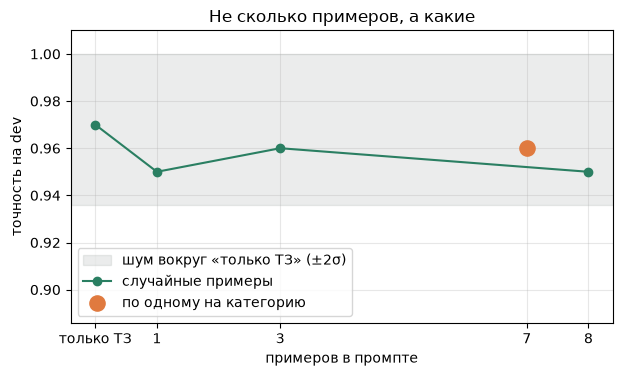

лучший вариант с примерами против одного ТЗ: -1 п.п.


In [13]:
xs = [0, 1, 3, 8]
ys = [ladder["2. написали ТЗ"]] + [few[k] for k in [1, 3, 8]]
plt.figure(figsize=(7, 3.8))
lo_, hi_ = (lambda p, n: (p - 2 * math.sqrt(p * (1 - p) / n), p + 2 * math.sqrt(p * (1 - p) / n)))(ys[0], len(DEV))
plt.axhspan(lo_, min(hi_, 1), color=GREY, alpha=.15, label="шум вокруг «только ТЗ» (±2σ)")
plt.plot(xs, ys, marker="o", color=GREEN, label="случайные примеры")
plt.scatter([7], [ladder["3. по примеру на категорию"]], s=120, color=ORANGE, zorder=3, label="по одному на категорию")
plt.xticks(xs + [7], ["только ТЗ", "1", "3", "8", "7"])
plt.ylim(min(ys + [lo_]) - 0.05, 1.01)
plt.xlabel("примеров в промпте"); plt.ylabel("точность на dev"); plt.grid(alpha=.3); plt.legend(loc="lower left")
plt.title("Не сколько примеров, а какие"); plt.show()
print(f"лучший вариант с примерами против одного ТЗ: {100 * (max(max(ys[1:]), ladder['3. по примеру на категорию']) - ys[0]):+.0f} п.п.")

Кто-то скажет: «больше примеров — лучше». Но есть нюанс: важно не только сколько, но и **какие**. Восемь случайных
примеров могут вообще не показать модели редкий класс — а семь продуманных, по одному на категорию, покажут все.

А если линия почти не поднялась над ТЗ — не удивляйтесь. Хорошее ТЗ уже сделало работу примеров. Примеры сильнее
всего там, где правило трудно сформулировать словами (тон, стиль, формат сложного ответа), или когда ТЗ нет вовсе.
Попробуйте дома few-shot поверх наивного промпта — разница будет совсем другой.

И ещё одна неприятная вещь. Возьмём **те же семь** примеров и просто поменяем их порядок.

In [14]:
orders = []
for seed in [1, 2, 3]:
    shuffled = per_class.sample(frac=1, random_state=seed)
    orders.append(evaluate(with_examples(shuffled), DEV)[0])
print("та же семёрка примеров в разном порядке:", [f"{a:.0%}" for a in orders])
print(f"разброс от одной перестановки: {100 * (max(orders) - min(orders)):.0f} п.п.")

та же семёрка примеров в разном порядке: ['95%', '95%', '94%']
разброс от одной перестановки: 1 п.п.


Смысл промпта не менялся ни на букву — только порядок. Запомним этот разброс: в разделе 5 разберёмся, много это
или мало и насколько вообще можно доверять таким цифрам.

А пока — обратно к Саше. Мы видели, что «думай» помогает. Но сколько это стоит?

## 3. Думать или не думать

Сначала подсмотрим, что модель «думает» про Сашу, когда ей разрешили рассуждать.

In [15]:
d = ollama("chat", messages=[{"role": "user", "content": SASHA + " Ответь только числом."}], think=True,
           options={"temperature": 0, "num_predict": 4000})
thinking = d["message"].get("thinking", "")
display(HTML(f'<div style="background:#fbf1ea;border-left:4px solid {ORANGE};padding:8px 12px;font-size:12px;'
             f'white-space:pre-wrap;max-height:260px;overflow:auto">{html.escape(thinking[:3000])}</div>'
             f'<p>💭 черновик: {len(thinking)} символов · ответ: <b>{html.escape(d["message"]["content"])}</b> · '
             f'всего токенов: {d["eval_count"]}</p>'))

Модель расписывает решение, перепроверяет себя, иногда передумывает — и только потом отвечает. Всё это
оплачено токенами, которые пользователь даже не увидит.

У нас четыре способа решить задачу:
- **сразу** — «ответь только числом»;
- **шаг за шагом** — просим рассуждать текстом и в конце дать ответ (chain-of-thought, Wei et al., 2022);
- **режим рассуждений** — модель сама пишет черновик в блоке `<think>` (этому её специально учили);
- **self-consistency** — пять рассуждений с температурой 0.7 и голосование (Wang et al., 2023).

Проверим на 16 задачах. Ответы посчитаем кодом, чтобы точно не ошибиться.

In [16]:
rng = random.Random(7)

def make_problem(kind):
    if kind == 0:
        a, b, p1, p2, d = rng.randint(2, 4), rng.randint(2, 4), rng.choice(range(800, 2000, 100)), \
                          rng.choice(range(2000, 5000, 100)), rng.choice([10, 20, 25])
        return (f"Саша купил {a} рубашки по {p1} рублей и {b} пары джинсов по {p2} рублей. На кассе скидка {d}% "
                f"на всю покупку. Сколько рублей Саша заплатил?", (a * p1 + b * p2) * (100 - d) // 100)
    if kind == 1:
        r, t, k = rng.choice([20, 25, 40, 50]), rng.randint(6, 15), rng.randint(3, 9)
        return (f"Насос перекачивает {r} литров в минуту. Бак на {r * t} литров начали наполнять, но через какое-то "
                f"время насос на {k} минут остановили, а потом включили снова. Сколько минут прошло от начала до "
                f"полного бака?", t + k)
    if kind == 2:
        n, m, x, y = rng.randint(5, 8), rng.randint(10, 24), rng.randint(3, 12), rng.randint(2, 4)
        return (f"В серверной {n} стоек по {m} серверов. {x} серверов сломались, а потом привезли ещё {y} стойки "
                f"по {m} исправных серверов. Сколько сейчас исправных серверов?", n * m - x + y * m)
    w, h, days, t = rng.choice([1000, 1500, 2000, 2500]), rng.randint(4, 12), rng.choice([10, 20, 30]), rng.randint(5, 9)
    return (f"Кондиционер мощностью {w} Вт работает {h} часов в день. Сколько рублей стоит его работа за {days} дней, "
            f"если киловатт-час стоит {t} рублей?", w * h * days * t // 1000)

PROBLEMS = [make_problem(i % 4) for i in range(16)]
pd.DataFrame(PROBLEMS, columns=["задача", "ответ"]).head(4)

,задача,ответ
0,Саша купил 3 рубашки по 1400 рублей и 2 пары джинсов по 4000 рублей. На кассе скидка 10% на всю покупку. Сколько руб...,10980
1,"Насос перекачивает 20 литров в минуту. Бак на 280 литров начали наполнять, но через какое-то время насос на 3 минут ...",17
2,"В серверной 7 стоек по 19 серверов. 3 серверов сломались, а потом привезли ещё 4 стойки по 19 исправных серверов. Ск...",206
3,"Кондиционер мощностью 1500 Вт работает 4 часов в день. Сколько рублей стоит его работа за 10 дней, если киловатт-час...",480


In [17]:
def last_number(text):
    nums = re.findall(r"\d[\d  ]*\d|\d", text.split("Ответ")[-1])
    return int(re.sub(r"\D", "", nums[-1])) if nums else None

def solve(q, mode):
    if mode == "сразу":
        a, n = chat(q + " Ответь только числом.", num_predict=50)
        return last_number(a), n
    if mode == "шаг за шагом":
        a, n = chat(q + " Решай шаг за шагом, в конце напиши «Ответ: N».", num_predict=1500)
        return last_number(a), n
    if mode == "режим рассуждений":
        a, n = chat(q + " Ответь только числом.", think=True, num_predict=4000)
        return last_number(a), n
    votes, total = [], 0
    for seed in range(5):                                   # self-consistency
        a, n = chat(q + " Решай шаг за шагом, в конце напиши «Ответ: N».", num_predict=1500, temperature=0.7, seed=seed)
        votes.append(last_number(a)); total += n
    return max(set(votes), key=votes.count), total

MODES = ["сразу", "шаг за шагом", "режим рассуждений", "5 × шаг за шагом + голосование"]
rows, per_mode = [], {}
for mode in MODES:
    t0 = time.time()
    res = per_mode[mode] = [solve(q, mode) for q, _ in PROBLEMS]
    rows.append({"способ": mode, "точность": np.mean([r[0] == a for r, (_, a) in zip(res, PROBLEMS)]),
                 "токенов на задачу": np.mean([r[1] for r in res]), "секунд на задачу": (time.time() - t0) / len(PROBLEMS)})
think_df = pd.DataFrame(rows)
think_df

,способ,точность,токенов на задачу,секунд на задачу
0,сразу,0.0000,2.9375,0.231278
1,шаг за шагом,0.9375,380.2500,4.948887
2,режим рассуждений,0.9375,1640.4375,22.489416
3,5 × шаг за шагом + голосование,0.9375,2113.3125,29.679065


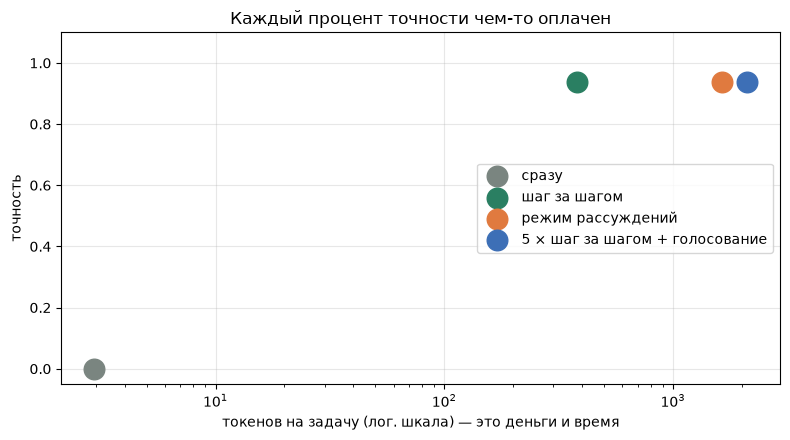

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = [GREY, GREEN, ORANGE, BLUE]
for (_, r), c in zip(think_df.iterrows(), colors):
    ax.scatter(r["токенов на задачу"], r["точность"], s=220, color=c, zorder=3, label=r["способ"])
ax.legend(loc="center right")
ax.set_xscale("log"); ax.set_xlabel("токенов на задачу (лог. шкала) — это деньги и время"); ax.set_ylabel("точность")
ax.set_ylim(-0.05, 1.1); ax.grid(alpha=.3); ax.set_title("Каждый процент точности чем-то оплачен")
plt.tight_layout(); plt.show()

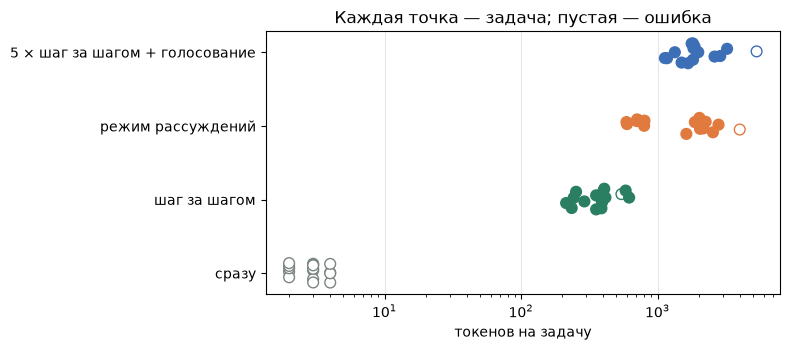

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, (mode, c) in enumerate(zip(MODES, colors)):
    toks = [n for _, n in per_mode[mode]]
    ok = [r[0] == a for r, (_, a) in zip(per_mode[mode], PROBLEMS)]
    ax.scatter(toks, np.full(len(toks), i) + np.random.uniform(-.15, .15, len(toks)),
               c=[c if o else "white" for o in ok], edgecolors=c, s=60)
ax.set_yticks(range(len(MODES)), MODES); ax.set_xscale("log"); ax.set_xlabel("токенов на задачу")
ax.set_title("Каждая точка — задача; пустая — ошибка"); ax.grid(alpha=.3, axis="x"); plt.tight_layout(); plt.show()

Вот и ответ на вопрос «всегда ли включать думай». Рассуждения — это **покупка точности за токены**. На арифметике
покупка окупается: «сразу» модель ошибается, а несколько сотен токенов рассуждений почти всегда спасают.

А теперь сравните три правые точки. Режим рассуждений и голосование стоят в разы дороже обычного «шаг за шагом» —
и на таких задачах часто не дают ничего сверху. Дороже не значит лучше. А на сложных задачах (как в ЛР3) модель
может и вовсе «утонуть в мыслях» и не ответить.

Правило для практики: **начинайте без рассуждений, включайте их только там, где измерили выигрыш, и всегда ставьте
лимит**. А для нашей классификации заявок думать не нужно — там нужна дисциплина ответа. Об этом дальше.

### 🏛️ Интерлюдия: музей промптинга
В 2023 году интернет был полон «секретных техник». Что с ними стало?

| Техника 2023 года | Что с ней сейчас |
| --- | --- |
| «Давай подумаем шаг за шагом» | встроено в модель: режим рассуждений, который мы только что видели |
| «Ты — лучший в мире эксперт…» | роль осталась в system-промпте, но чудес не даёт; важнее описать задачу |
| «Ответь строго в формате JSON, пожалуйста!!!» | ограниченное декодирование и JSON Schema — следующий раздел |
| «Дам $200 чаевых» и «от этого зависит моя карьера» | эффект на современных моделях — на уровне шума (проверим в разделе 5) |
| Tree-of-Thoughts, ручные цепочки рассуждений | ушли в агентные циклы и обучение моделей-рассуждателей |
| Подбор промпта руками | автоматический подбор: APE, OPRO, DSPy — раздел 6 |

Мораль: модели стали лучше понимать нормальные инструкции, и «магические слова» умерли. Остались инженерные вещи:
ясное ТЗ, примеры, формат, измерения.

## 4. JSON, который не ломается никогда

Классика: турагентство, поток заявок, нужно разложить каждую по полям. Вот четыре заявки из прошлогодней лекции и восемь похожих.

In [20]:
TOURS = [
    "Хотелось бы отдохнуть где-то в теплой стране где не нужна виза, например ОАЭ или Мальдивы, важно чтобы было все включено, тур должен быть на 5 человек (2 номера) и 10 дней. Бюджет 500-700 тыс. руб. Отель должен быть только 5 звезд.",
    "Добрый день! Рассматриваем возможность отпуска в Греции. Хотим забронировать тур на 7 человек (три номера) на 14 дней. Обязательно нужен отель уровня 5 звезд с системой «ультра всё включено». Бюджет — 1,2–1,5 млн рублей.",
    "Здравствуйте! Хочу организовать недорогой отдых в Турции. Рассчитываю на 4-х человек (два номера). Продолжительность тура — 7 дней. Отель: 3 звезды, без завтрака. Бюджет: до 300 тысяч рублей.",
    "Здравствуйте! Ищу эксклюзивный отдых в самом сердце Парижа. Тур на двоих, длительность — 7 дней. Отель: 5 звезд, люксовый номер с видом на Эйфелеву башню, полный пансион. Бюджет: до 2,5 млн рублей.",
    "Хотим в Сочи или Анапу на 5–7 дней, вдвоём, бюджет до 150 тысяч, отель 4 звезды, только завтраки.",
    "Ищем тур в Египет на 7 дней, семья из четырёх человек, всё включено, звёздность не важна, уложиться бы в 400 тыс.",
    "Добрый день! Нужен отдых в Таиланде на 12 ночей, отель 5*, полупансион, бюджет 600–800 тысяч.",
    "Хочу в Стамбул на выходные, дня на 2–3, отель 3 звезды, без питания, бюджет 90 000 ₽.",
    "Планируем поездку по Италии: Рим и Флоренция, 10 дней, гостиницы 4 звезды с завтраком, денег около 1 млн.",
    "Корпоратив на 30 человек в Казани, 3 дня, полный пансион, отель 4 звезды, бюджет до 2 млн рублей.",
    "Мальдивы, медовый месяц, 9 дней, вилла на воде, ультра всё включено, о деньгах не думаем.",
    "Нужна Абхазия или Грузия, дней 8–10, бюджет 120 тыс., отель любой, питание — завтрак и ужин.",
]
GOLD = [  # места, бюджет (максимум), дней от, дней до, звёзды, питание
    (["Мальдивы", "ОАЭ"], 700000, 10, 10, 5, "AI"), (["Греция"], 1500000, 14, 14, 5, "UAI"),
    (["Турция"], 300000, 7, 7, 3, "RO"), (["Париж"], 2500000, 7, 7, 5, "FB"),
    (["Анапа", "Сочи"], 150000, 5, 7, 4, "BB"), (["Египет"], 400000, 7, 7, None, "AI"),
    (["Таиланд"], 800000, 12, 12, 5, "HB"), (["Стамбул"], 90000, 2, 3, 3, "RO"),
    (["Рим", "Флоренция"], 1000000, 10, 10, 4, "BB"), (["Казань"], 2000000, 3, 3, 4, "FB"),
    (["Мальдивы"], None, 9, 9, None, "UAI"), (["Абхазия", "Грузия"], 120000, 8, 10, None, "HB"),
]
FIELDS = ["places", "budget_rub", "days_min", "days_max", "stars", "food"]
RULES = ('Поля: places — список мест по алфавиту; budget_rub — максимальный бюджет в рублях числом; '
         'days_min и days_max — длительность в днях (если одно число — оба одинаковые); stars — звёзды отеля 1–5; '
         'food — тип питания: RO (без питания), BB (завтрак), HB (завтрак и ужин), FB (трёхразовое), '
         'AI (всё включено), UAI (ультра всё включено). Если поле не указано — null.')

Сначала по-простому: попросим «ответь в формате JSON» и попробуем разобрать ответ.

🗳️ **Ваш прогноз.** Сколько из 12 ответов вообще получится прочитать как JSON с нужными полями?

In [21]:
ask_json = ChatPromptTemplate.from_messages([
    ("human", "Разбери заявку в турагентство и ответь в формате JSON. " + RULES + "\n\nЗаявка: {text}")
]) | llm | StrOutputParser()

def try_parse(answer):          # так пишет каждый в первый раз
    try:
        d = json.loads(answer)
    except json.JSONDecodeError:
        return None
    return d if isinstance(d, dict) and set(FIELDS) <= set(d) else None

raw_answers = ask_json.batch([{"text": t} for t in TOURS])
parsed = [try_parse(a) for a in raw_answers]
print(f"разобралось с нужными полями: {sum(p is not None for p in parsed)} из {len(TOURS)}")
print("\nпример ответа:\n" + raw_answers[1][:400])

разобралось с нужными полями: 0 из 12

пример ответа:
```json
{
  "places": [
    "Греция"
  ],
  "budget_rub": 1500000,
  "days_min": 14,
  "days_max": 14,
  "stars": 5,
  "food": "UAI",
  "guests": 7
}
```


In [22]:
def why(answer):
    if try_parse(answer):
        return "✓"
    a = answer.strip()
    m = re.search(r"\{.*\}", a, re.S)
    if not m:
        return "нет JSON вообще"
    try:
        d = json.loads(m.group(0))
    except json.JSONDecodeError as e:
        return f"сломанный JSON: {e.msg}"
    if set(FIELDS) - set(d):
        return "не те поля: " + ", ".join(sorted(set(FIELDS) - set(d)))
    return "обёрнут в ```json" if a.startswith("```") else "текст вокруг JSON"

pd.DataFrame({"заявка": [t[:50] + "…" for t in TOURS], "диагноз": [why(a) for a in raw_answers]})

,заявка,диагноз
0,Хотелось бы отдохнуть где-то в теплой стране где н…,обёрнут в ```json
1,Добрый день! Рассматриваем возможность отпуска в Г…,обёрнут в ```json
2,Здравствуйте! Хочу организовать недорогой отдых в …,обёрнут в ```json
3,Здравствуйте! Ищу эксклюзивный отдых в самом сердц…,обёрнут в ```json
4,"Хотим в Сочи или Анапу на 5–7 дней, вдвоём, бюджет…",обёрнут в ```json
5,"Ищем тур в Египет на 7 дней, семья из четырёх чело…",обёрнут в ```json
6,"Добрый день! Нужен отдых в Таиланде на 12 ночей, о…",обёрнут в ```json
7,"Хочу в Стамбул на выходные, дня на 2–3, отель 3 зв…",обёрнут в ```json
8,"Планируем поездку по Италии: Рим и Флоренция, 10 д…",обёрнут в ```json
9,"Корпоратив на 30 человек в Казани, 3 дня, полный п…",обёрнут в ```json


Модель вежливо заворачивает JSON в markdown, дописывает «Вот ваш JSON:», иногда переименовывает поля.
Кто-то скажет: вырежем регуляркой от `{` до `}`! Так делают все — ровно до того дня, когда модель вставит в ответ
два JSON, забудет закрыть скобку или назовёт поле `budget` вместо `budget_rub`. Для одного запроса в чате терпимо,
для конвейера на тысячу заявок — катастрофа. Нужна **гарантия**.

### Ограниченное декодирование
Решение — не уговаривать модель, а **запретить** ей ошибаться. Мы отдаём движку JSON Schema, и на каждом шаге
генерации он просто вычёркивает токены, которые нарушили бы схему. Модель физически не может написать
`"food": "обычно всё"` — разрешены только шесть вариантов.

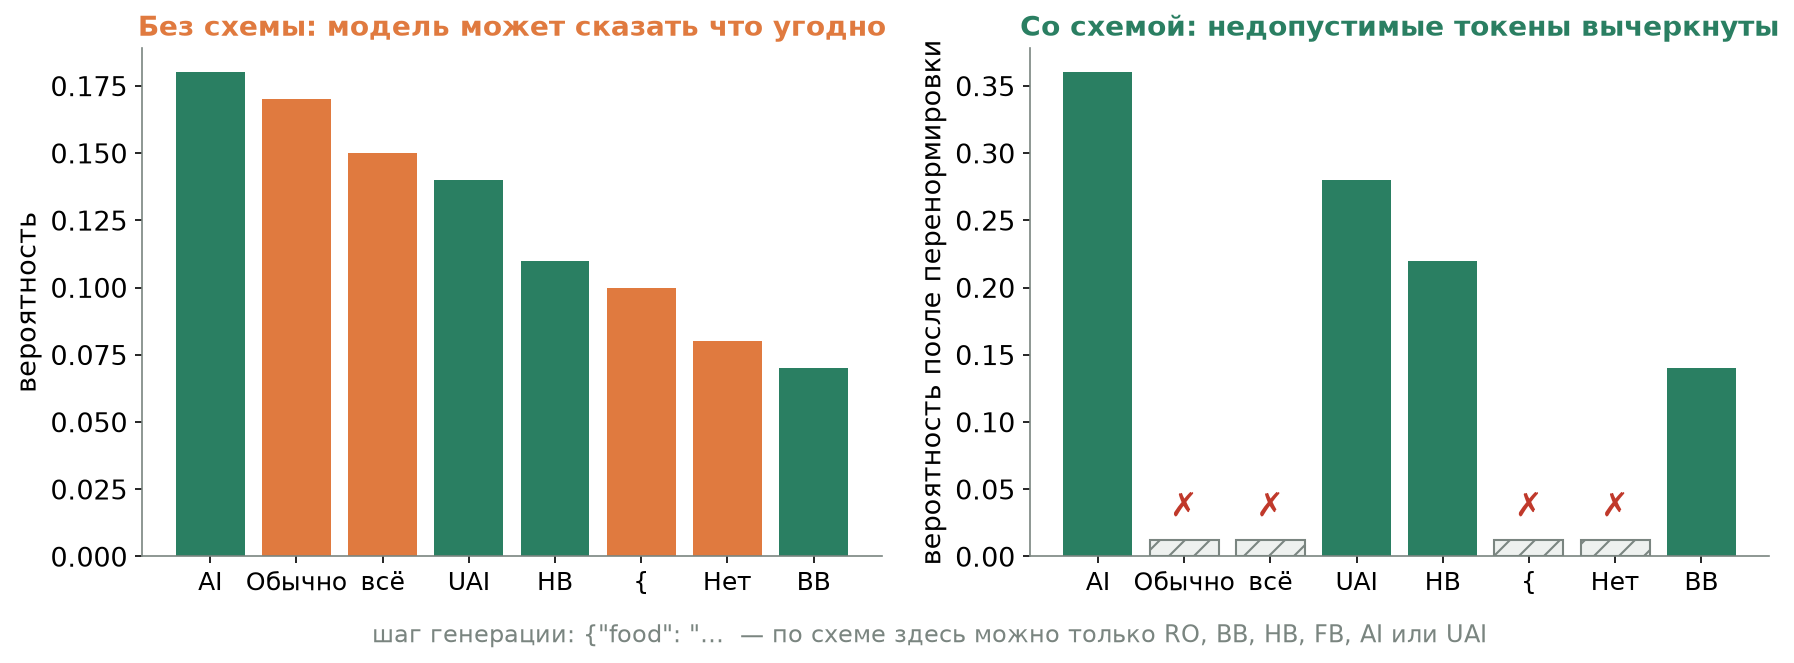

*Ограниченное декодирование: недопустимые по схеме токены получают нулевую вероятность*

Схему удобно описывать классом Pydantic: тот же класс потом проверяет и типизирует ответ. LangChain связывает всё
одной строчкой — `with_structured_output`.

In [23]:
from typing import Literal, Optional
from pydantic import BaseModel, Field

class Tour(BaseModel):
    places: list[str] = Field(description="места по алфавиту")
    budget_rub: Optional[int] = Field(description="максимальный бюджет в рублях")
    days_min: Optional[int]
    days_max: Optional[int]
    stars: Optional[int] = Field(ge=1, le=5)
    food: Optional[Literal["RO", "BB", "HB", "FB", "AI", "UAI"]]

print(json.dumps(Tour.model_json_schema()["properties"]["food"], ensure_ascii=False))   # это уйдёт в движок

structured = ChatPromptTemplate.from_messages([
    ("system", "Разбери заявку в турагентство. " + RULES), ("human", "{text}")
]) | llm.with_structured_output(Tour, method="json_schema")

tours = structured.batch([{"text": t} for t in TOURS], return_exceptions=True)
print(f"разобралось: {sum(isinstance(t, Tour) for t in tours)} из {len(TOURS)}")
tour_df = pd.DataFrame([t.model_dump() if isinstance(t, Tour) else {f: None for f in FIELDS} for t in tours])
tour_df

{"anyOf": [{"enum": ["RO", "BB", "HB", "FB", "AI", "UAI"], "type": "string"}, {"type": "null"}], "title": "Food"}


разобралось: 12 из 12


,places,budget_rub,days_min,days_max,stars,food
0,"[ОАЭ, Мальдивы]",700000.0,10,10,5.0,AI
1,[Греция],1500000.0,14,14,5.0,UAI
2,[Турция],300000.0,7,7,3.0,RO
3,[Париж],2500000.0,7,7,5.0,FB
4,"[Анапа, Сочи]",150000.0,5,7,4.0,BB
5,[Египет],400000.0,7,7,NaN,FB
6,[Таиланд],700000.0,12,12,5.0,BB
7,[Стамбул],90000.0,2,3,3.0,RO
8,"[Рим, Флоренция]",1000000.0,10,10,4.0,BB
9,[Казань],2000000.0,3,3,4.0,FB


12 из 12. Но не обольщайтесь: схема гарантирует **формат**, а не **правду**. Проверим поля по эталону.

In [24]:
gold_df = pd.DataFrame(GOLD, columns=FIELDS)
norm = lambda v: sorted(v) if isinstance(v, list) else (None if v is None or (isinstance(v, float) and math.isnan(v)) else v)
hits = pd.DataFrame({f: [norm(p) == norm(g) for p, g in zip(tour_df[f], gold_df[f])] for f in FIELDS})
hits.index = [t[:40] + "…" for t in TOURS]
print("точность по полям:", {f: f"{hits[f].mean():.0%}" for f in FIELDS})
hits.style.format(lambda v: "✓" if v else "✗") \
    .map(lambda v: f"background-color:{'#d7ece4' if v else '#f6d8d4'};color:{GREEN if v else RED}")

точность по полям: {'places': '100%', 'budget_rub': '92%', 'days_min': '100%', 'days_max': '100%', 'stars': '100%', 'food': '83%'}


,places,budget_rub,days_min,days_max,stars,food
Хотелось бы отдохнуть где-то в теплой ст…,✓,✓,✓,✓,✓,✓
Добрый день! Рассматриваем возможность о…,✓,✓,✓,✓,✓,✓
Здравствуйте! Хочу организовать недорого…,✓,✓,✓,✓,✓,✓
Здравствуйте! Ищу эксклюзивный отдых в с…,✓,✓,✓,✓,✓,✓
"Хотим в Сочи или Анапу на 5–7 дней, вдво…",✓,✓,✓,✓,✓,✓
"Ищем тур в Египет на 7 дней, семья из че…",✓,✓,✓,✓,✓,✗
Добрый день! Нужен отдых в Таиланде на 1…,✓,✗,✓,✓,✓,✗
"Хочу в Стамбул на выходные, дня на 2–3, …",✓,✓,✓,✓,✓,✓
Планируем поездку по Италии: Рим и Флоре…,✓,✓,✓,✓,✓,✓
"Корпоратив на 30 человек в Казани, 3 дня…",✓,✓,✓,✓,✓,✓


Формат идеальный, а ошибки по сути остались — обычно в бюджете с диапазоном, в звёздах, когда их не назвали,
и в местах. Схема убирает целый класс проблем — «не тот формат», — но думать за модель не будет.
Именно это вы будете доводить до совершенства в ЛР1.

Применим схему и к нашим заявкам: категория — поле с семью допустимыми значениями.

In [25]:
class Category(BaseModel):
    category: Literal["ремонт", "техобслуживание", "монтаж", "демонтаж", "гарантийный случай", "консультация", "запчасти"]

cat_schema = (ChatPromptTemplate.from_messages([
    ("system", SPEC),
    FewShotChatMessagePromptTemplate(
        example_prompt=ChatPromptTemplate.from_messages([("human", "{text}"), ("ai", '{{"category": "{category}"}}')]),
        examples=[{"text": r.text, "category": r.category} for r in per_class.itertuples()]),
    ("human", "{text}")]) | llm.with_structured_output(Category, method="json_schema") | (lambda c: c.category))

acc, bad, _ = evaluate(cat_schema, DEV, "4. + JSON Schema")
print(f"точность {acc:.0%}, ответов не из списка {bad:.0%}")

точность 97%, ответов не из списка 0%


«Не из списка» — ровно ноль, и уже никогда не будет больше. Точность может почти не измениться — схема добавляет
надёжность, а не ум.

Стоп. А «почти не изменилась» — это сколько? Если на одной технике 78%, а на другой 81% — это прогресс или шум?

## 5. Цифры врут? Промпт как эксперимент

У нас 100 примеров в dev. Каждый пример — это монетка: угадала или нет. При точности $p$ на $n$ примерах
стандартная ошибка оценки примерно $\sqrt{p(1-p)/n}$. Для $p = 0{,}8$ и $n = 100$ это **4 процентных пункта**.
Значит, разница в 3% между двумя промптами — это, скорее всего, шум.

Не верите формуле? Проверим симуляцией: пусть у модели **истинная** точность ровно 80%, и мы десять тысяч раз меряем её
на случайных ста примерах.

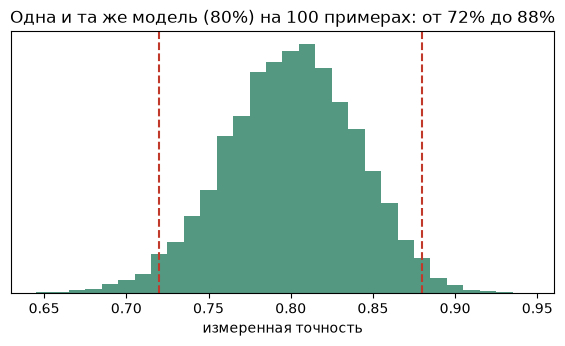

In [26]:
sim = np.random.default_rng(0).binomial(100, 0.8, size=10_000) / 100
plt.figure(figsize=(7, 3.4))
plt.hist(sim, bins=np.arange(0.645, 0.95, 0.01), color=GREEN, alpha=.8)
lo95, hi95 = np.percentile(sim, [2.5, 97.5])
for v in (lo95, hi95):
    plt.axvline(v, color=RED, ls="--")
plt.title(f"Одна и та же модель (80%) на 100 примерах: от {lo95:.0%} до {hi95:.0%}")
plt.xlabel("измеренная точность"); plt.yticks([]); plt.show()

Одна и та же модель может показать и 72%, и 88% — просто из-за того, какие примеры попались.

Теперь на настоящей модели. Возьмём **одно и то же** ТЗ и запишем его пятью способами (плюс шестой — с чаевыми): смысл тот же, меняется только оформление.
Исследования показывают, что у небольших моделей одна смена форматирования может двигать точность на десятки пунктов
(Sclar et al., 2023).

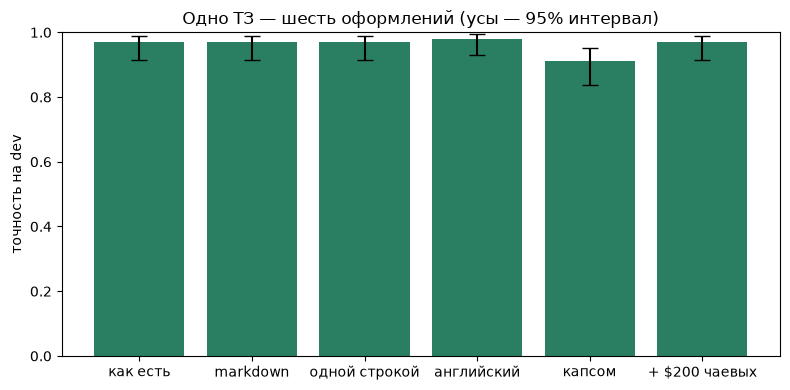

{'как есть': 0.97,
 'markdown': 0.97,
 'одной строкой': 0.97,
 'английский': 0.98,
 'капсом': 0.91,
 '+ $200 чаевых': 0.97}

In [27]:
BODY = SPEC.split("Категории:")[1]
FORMATS = {
    "как есть": SPEC,
    "markdown": "# Роль\nДиспетчер сервисной компании.\n# Задача\nОпредели категорию обращения.\n# Категории" + BODY,
    "одной строкой": "Ты диспетчер, определи категорию: " + " ".join(BODY.split()),
    "английский": ("You are a dispatcher at an equipment service company. Classify the customer request into one category "
                   "(answer with the Russian name exactly):" + BODY),
    "капсом": SPEC.upper(),
    "+ $200 чаевых": SPEC + "\n\nЯ дам тебе $200 чаевых за правильный ответ. От этого зависит моя карьера!",
}

def wilson(p, n, z=1.96):
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

fmt = {name: evaluate(ChatPromptTemplate.from_messages([("system", s), ("human", "{text}")]) | llm | StrOutputParser(),
                      DEV)[0] for name, s in FORMATS.items()}
lo, hi = zip(*[wilson(p, len(DEV)) for p in fmt.values()])
plt.figure(figsize=(8, 4))
plt.bar(fmt.keys(), fmt.values(), color=GREEN,
        yerr=[np.array(list(fmt.values())) - lo, np.array(hi) - np.array(list(fmt.values()))], capsize=6)
plt.ylim(0, 1); plt.ylabel("точность на dev"); plt.title("Одно ТЗ — шесть оформлений (усы — 95% интервал)")
plt.tight_layout(); plt.show()
fmt

Смотрите на «усы»: где они перекрываются, разницу нельзя отличить от шума ста примеров. Чаевые — не исключение.
Если какой-то вариант всё же заметно выбился — посмотрите, какой. Например, текст капсом модель видит совсем
другими токенами (вспомните лекцию 1): для неё это почти другой язык.
А теперь самое неприятное: посмотрим под этим углом на нашу лестницу.

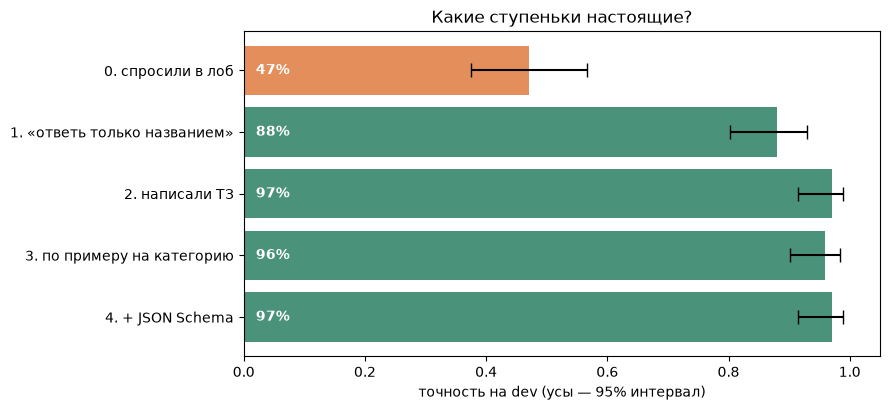

In [28]:
def ladder_plot(title):
    steps = pd.Series(ladder)
    lo, hi = np.array([wilson(p, len(DEV)) for p in steps.values]).T
    fig, ax = plt.subplots(figsize=(9, 0.6 * len(steps) + 1.2))
    y = np.arange(len(steps))[::-1]
    ax.barh(y, steps.values, color=[ORANGE] + [GREEN] * (len(steps) - 1), alpha=.85)
    ax.errorbar(steps.values, y, xerr=[steps.values - lo, hi - steps.values], fmt="none", ecolor="black", capsize=5)
    for yi, v in zip(y, steps.values):
        ax.text(0.02, yi, f"{v:.0%}", va="center", color="white", weight="bold")
    ax.set_yticks(y, steps.index); ax.set_xlim(0, 1.05); ax.set_xlabel("точность на dev (усы — 95% интервал)")
    ax.set_title(title); plt.tight_layout(); plt.show()

ladder_plot("Какие ступеньки настоящие?")

Скачок от «спросили в лоб» к ТЗ обычно виден невооружённым глазом: «усы» не пересекаются. А вот дальше ступеньки
часто тонут в шуме. Это не значит, что примеры и схема бесполезны — это значит, что **ста примеров мало**, чтобы
доказать их пользу. Отсюда три правила честного эксперимента:

1. **Отдельный тест.** Подбираем на dev, а итог меряем один раз на отложенном test.
2. **Доверительные интервалы.** Разница, которая меньше «усов», — не улучшение.
3. **Повторы.** Если модель сэмплирует (температура > 0), прогоните несколько сидов.

In [29]:
seed_runs = [evaluate(ChatPromptTemplate.from_messages([("system", SPEC), ("human", "{text}")])
                      | ChatOllama(model=MODEL, temperature=0.7, seed=s, reasoning=False) | StrOutputParser(), DEV)[0]
             for s in [1, 2, 3]]
print("один и тот же промпт, T = 0.7, три сида:", [f"{a:.0%}" for a in seed_runs])

один и тот же промпт, T = 0.7, три сида: ['96%', '95%', '97%']


Даже без изменения промпта результат прыгает. Теперь вы знаете, почему в ЛР лидерборд делится на публичную
и закрытую части — и почему подгонять промпт под публичную опасно.

Ну хорошо. Подбирать промпт руками долго и скучно. А что если поручить это самой модели?

## 6. Модель сама улучшает свой промпт

Мета-промптинг: модель пишет инструкцию для себя же. Простейшая рабочая схема (APE, Zhou et al., 2022;
OPRO, Yang et al., 2023): показываем модели прошлые инструкции с их баллами и примеры ошибок и просим написать
новую, получше. Новую оцениваем на dev — и по кругу.

Устроим модели экзамен: дадим ей **наивную** инструкцию «определи категорию» — ту, с которой мы начинали, — и
посмотрим, сможет ли она сама дойти до уровня нашего ТЗ, которое мы писали головой.

🗳️ **Ваш прогноз.** Догонит модель человека за три раунда?

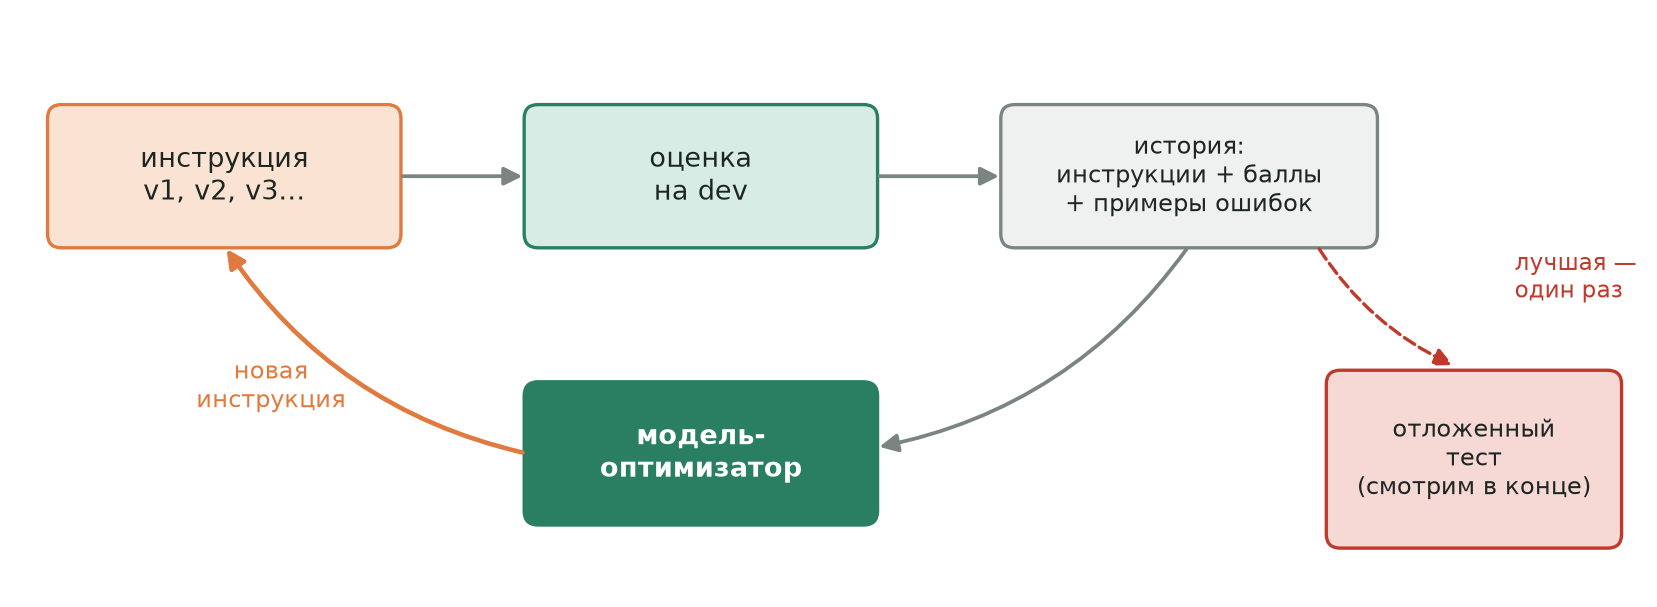

*Цикл мета-промптинга. Тест в цикле не участвует — иначе мы обманем сами себя*

In [30]:
OPTIMIZER = '''Ты улучшаешь инструкцию для модели, которая определяет категорию обращения клиента сервисной компании.
Допустимые категории: {cats}.

Предыдущие инструкции и их точность на проверочном наборе:
{history}

Обращения, на которых лучшая инструкция ошиблась (текст → правильно → ответ модели):
{errors}

Напиши новую инструкцию, которая исправит эти ошибки и будет точнее всех предыдущих.
Выведи только текст инструкции.'''
optimizer = ChatPromptTemplate.from_template(OPTIMIZER) | ChatOllama(model=MODEL, temperature=0.8, reasoning=False) \
            | StrOutputParser()

def as_system(instruction):          # фигурные скобки в тексте LangChain принял бы за переменные
    return ("system", instruction.replace("{", "{{").replace("}", "}}"))

def score(instruction, df):
    chain = ChatPromptTemplate.from_messages([as_system(instruction), ("human", "{text}")]) | llm | StrOutputParser()
    acc, _, preds = evaluate(chain, df)
    return acc, preds

history = [(NAIVE, ladder["0. спросили в лоб"], preds_naive)]       # стартуем с наивной инструкции!
for round_ in range(3):
    best_text, best_acc, best_preds = max(history, key=lambda h: h[1])
    errors = "\n".join([f"- {t[:200]!r} → {g} → {p}"
                        for t, g, p in zip(DEV.text, DEV.category, best_preds) if g != p][:6])
    hist = "\n\n".join(f"[точность {a:.0%}]\n{t}" for t, a, _ in sorted(history, key=lambda h: h[1])[-3:])
    for cand in range(2):
        new = optimizer.invoke({"cats": ", ".join(CATS), "history": hist, "errors": errors})
        acc, preds = score(new, DEV)
        history.append((new, acc, preds))
        print(f"раунд {round_ + 1}, кандидат {cand + 1}: dev {acc:.0%}")
best_text, best_acc, _ = max(history, key=lambda h: h[1])
ladder["5. промпт написала сама модель"] = best_acc
print("\nлучшая инструкция:\n" + best_text[:800])

раунд 1, кандидат 1: dev 84%


раунд 1, кандидат 2: dev 94%


раунд 2, кандидат 1: dev 84%


раунд 2, кандидат 2: dev 91%


раунд 3, кандидат 1: dev 73%


раунд 3, кандидат 2: dev 72%

лучшая инструкция:
Определи категорию обращения клиента к сервисной компании, строго используя один из следующих вариантов: **ремонт**, **техобслуживание**, **монтаж**, **демонтаж**, **гарантийный случай**, **консультация**, **запчасти**.

Анализировать текст запроса с учетом контекста и ключевых слов:
- Если клиент просит просто поговорить, задать вопрос или получить совет без вызова специалиста для выполнения работ — выбирайте **консультация**.
- Если клиент сообщает о проблеме с оборудованием (шум, падение давления, поломка) и готов оплатить срочный выезд мастера для устранения неисправности — выбирайте **ремонт**.
- Если клиент заказывает установку нового оборудования, подключение к коммуникациям или проведение плановых работ — выбирайте **монтаж**.
- Если клиент просит снять оборудование со здания или у


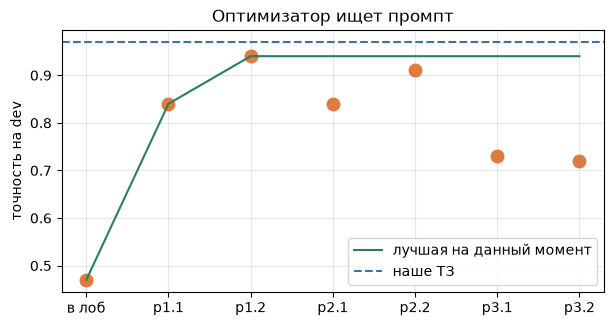

In [31]:
accs = [a for _, a, _ in history]
plt.figure(figsize=(7, 3.4))
plt.plot(range(len(accs)), accs, "o", color=ORANGE, ms=9)
plt.plot(range(len(accs)), np.maximum.accumulate(accs), "-", color=GREEN, label="лучшая на данный момент")
plt.axhline(ladder["2. написали ТЗ"], color=BLUE, ls="--", label="наше ТЗ")
plt.xticks(range(len(accs)), ["в лоб"] + [f"р{i // 2 + 1}.{i % 2 + 1}" for i in range(len(accs) - 1)])
plt.ylabel("точность на dev"); plt.grid(alpha=.3); plt.legend(); plt.title("Оптимизатор ищет промпт"); plt.show()

Посмотрите на лучшую инструкцию: модель сама придумала определения категорий, почти как мы в разделе 1.
Но честный ли это результат — или мы подогнали инструкцию под эти конкретные сто заявок? Мы выбрали лучшую из
семи по dev, а максимум из семи шумных чисел всегда оптимистичен. Ответ может дать только **тест**, который цикл
ни разу не видел. Открываем.

🗳️ **Ваш прогноз.** Удержится ли результат на тесте?

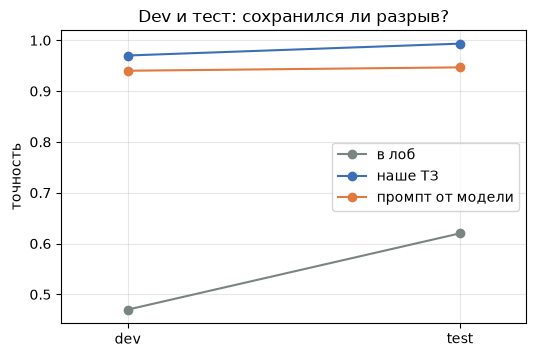

,dev,test
в лоб,0.47,0.620000
наше ТЗ,0.97,0.993333
промпт от модели,0.94,0.946667


In [32]:
naive_test, _ = score(NAIVE, TEST)
start_test, _ = score(SPEC, TEST)
best_test, _ = score(best_text, TEST)
res = pd.DataFrame({"dev": [ladder["0. спросили в лоб"], ladder["2. написали ТЗ"], best_acc],
                    "test": [naive_test, start_test, best_test]},
                   index=["в лоб", "наше ТЗ", "промпт от модели"])
fig, ax = plt.subplots(figsize=(6, 3.8))
for name, c in zip(res.index, [GREY, BLUE, ORANGE]):
    ax.plot([0, 1], res.loc[name], marker="o", color=c, label=name)
ax.set_xticks([0, 1], ["dev", "test"]); ax.set_xlim(-0.2, 1.2); ax.set_ylabel("точность"); ax.grid(alpha=.3)
ax.legend(); ax.set_title("Dev и тест: сохранился ли разрыв?"); plt.show()
res

Сравнивайте не dev с тестом, а линии между собой: тест целиком может оказаться проще или сложнее (смотрите, как
сдвинулась серая линия «в лоб»). Важно, сохранился ли **разрыв**. Если оранжевая линия отстала от синей сильнее,
чем на dev, — это **переобучение промпта**: цикл научился угождать dev-набору. Если удержалась — модель
действительно сама нашла рабочую формулировку, начав с одной строчки.

Мета-промптинг — мощный инструмент, но только с отложенным тестом. В индустрии для этого есть целые фреймворки
(DSPy, GEPA), и все они держатся на том же правиле.

Окей, мы научились ставить задачу одному вызову модели. Но всё чаще модель не просто отвечает, а **действует**.

## 7. Промпт для агента: описание инструмента — тоже промпт

Агенту (лекция 6) мы даём инструменты — функции, которые он может вызывать. Как модель решает, какую вызвать?
По **описанию**. А описание — это просто текст, то есть промпт. Посмотрим, что будет с плохими описаниями.

In [33]:
from langchain_core.tools import tool

@tool
def f1(text: str) -> str:
    "Функция 1."
    return "ok"

@tool
def f2(text: str) -> str:
    "Функция 2."
    return "ok"

@tool
def create_visit(problem: str) -> str:
    "Оформить выезд мастера: использовать, когда у клиента что-то сломалось или нужен монтаж или ТО."
    return "ok"

@tool
def answer_question(question: str) -> str:
    "Ответить на вопрос клиента без выезда: цены, сроки, как выбрать оборудование."
    return "ok"

QUERIES = ["У нас течёт кондиционер, приезжайте завтра.", "Сколько стоит чистка сплит-системы?",
           "Нужно установить новый бойлер в квартире.", "Какой ИБП лучше взять для серверной?"]
rows = []
for name, tools in [("плохие описания", [f1, f2]), ("хорошие описания", [create_visit, answer_question])]:
    bound = llm.bind_tools(tools)
    for q in QUERIES:
        calls = bound.invoke(q).tool_calls
        rows.append({"описания": name, "запрос": q, "вызвала": calls[0]["name"] if calls else "— ничего"})
pd.DataFrame(rows).pivot(index="запрос", columns="описания", values="вызвала")

описания,плохие описания,хорошие описания
запрос,,
Какой ИБП лучше взять для серверной?,— ничего,— ничего
Нужно установить новый бойлер в квартире.,f1,create_visit
Сколько стоит чистка сплит-системы?,f1,answer_question
"У нас течёт кондиционер, приезжайте завтра.",f1,create_visit


С «функцией 1» и «функцией 2» модель гадает. С нормальными описаниями — выбирает осмысленно (а на простой вопрос
может и вовсе ответить сама, без инструмента, — это тоже законный выбор). Всё, что мы сегодня
говорили про ТЗ, работает и здесь: описание инструмента — это маленькое ТЗ, и писать его надо так же тщательно.
Подробно про агентов — в лекции 6.

И последнее. Промпт, который работает, надо как-то **сохранить работающим**.

## 8. Промпт как код

В настоящем проекте промпт живёт месяцами, и его постоянно правят. Как узнать, что правка ничего не сломала?
Так же, как с кодом, — **тестами**. Самый полезный тест для промпта — прогнать старую и новую версию на одном
наборе и посмотреть на **разницу ответов**: что изменилось, где стало лучше, где хуже.

Сценарий из жизни: бизнес попросил добавить восьмую категорию — «диагностика». Одна строчка в ТЗ. Что может пойти не так?

In [34]:
SPEC_V2 = SPEC.replace("- запчасти — клиент хочет купить деталь.",
                       "- запчасти — клиент хочет купить деталь;\n"
                       "- диагностика — нужно выяснить, почему оборудование работает неправильно.")
CATS_V2 = CATS + ["диагностика"]

def prompt_diff(old, new, df, new_cats):
    run = lambda instr: ChatPromptTemplate.from_messages([as_system(instr), ("human", "{text}")]) | llm | StrOutputParser()
    a = [to_label(x) for x in run(old).batch([{"text": t} for t in df.text], config={"max_concurrency": 4})]
    b = [to_label(x, new_cats) for x in run(new).batch([{"text": t} for t in df.text], config={"max_concurrency": 4})]
    rows = [(t, g, x, y) for t, g, x, y in zip(df.text, df.category, a, b) if x != y]
    better = sum(y == g for _, g, _, y in rows); worse = sum(x == g for _, g, x, _ in rows)
    color = lambda v, g: GREEN if v == g else RED
    cells = "".join(f'<tr><td>{html.escape(t[:110])}…</td><td>{g}</td><td style="color:{color(x, g)}">{x}</td>'
                    f'<td style="color:{color(y, g)};font-weight:bold">{y}</td></tr>' for t, g, x, y in rows)
    display(HTML(f'<b>Изменилось ответов: {len(rows)} из {len(df)} · стало лучше: {better} · стало хуже: {worse}</b>'
                 f'<table><tr><th>обращение</th><th>по разметке</th><th>было</th><th>стало</th></tr>{cells}</table>'))

prompt_diff(SPEC, SPEC_V2, DEV, CATS_V2)

обращение,по разметке,было,стало
Здравствуйте! В нашем офисном центре в Краснодаре вознкила проблема с чиллером trane: у него очень сильно шу…,ремонт,ремонт,диагностика
"Бесперебойник в самарском корпусе при любой проверке сразу переходит на батарею, нужно выяснить причину и восс…",ремонт,ремонт,диагностика
"Здравствуйте! В нашей серверной приточная установка стала сильно шуметь во время работы, и мы опасаемся перегр…",ремонт,ремонт,диагностика


Одна строчка — и часть старых заявок тихо переехала в новую категорию. Это то, чего хотел бизнес, или поломка?
Зависит от того, как теперь размечать «ремонт с диагностикой». Но главное — вы узнали об этом **до релиза**,
а не из жалобы клиента, чья заявка ушла не тому мастеру.

Правило: у каждого промпта в проекте есть версия, набор для проверки и diff ответов при каждой правке. В лекции 8
соберём из этого настоящую систему оценки с трассировкой, а пока запомните: **промпт без тестов — это код без тестов**.

## 🪜 Лестница качества
Вернёмся к нашим ста заявкам. Вот что мы из них выжали — той же самой моделью, без обучения.

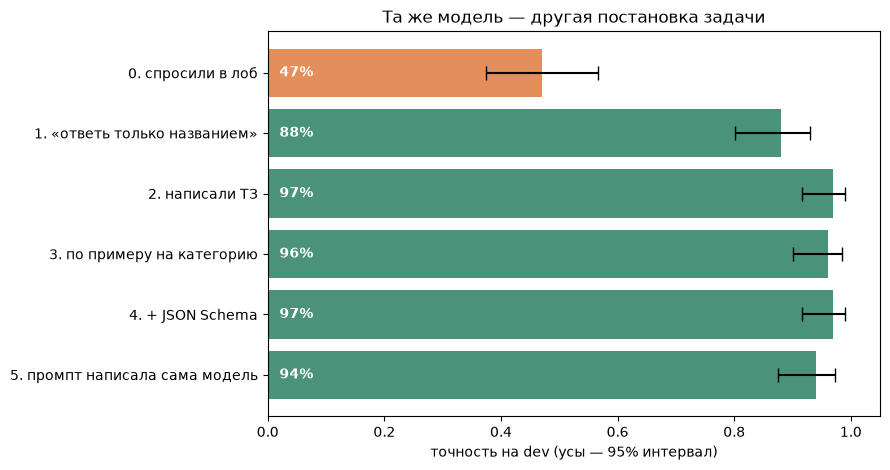

на отложенном тесте: в лоб 62%, наше ТЗ 99%, промпт от модели 95%


In [35]:
ladder_plot("Та же модель — другая постановка задачи")
print(f"на отложенном тесте: в лоб {naive_test:.0%}, наше ТЗ {start_test:.0%}, промпт от модели {best_test:.0%}")

## Итоги

- **Сначала формат.** Одна фраза «ответь только названием» может дать больше, чем все остальные трюки вместе.
- **Промпт — это ТЗ**: роль, классы с определениями, правила для спорных случаев, формат ответа.
- **Примеры** важны не количеством, а составом; после хорошего ТЗ их вклад может утонуть в шуме.
- **Думать — значит платить.** Рассуждения покупают точность за токены; включайте их там, где измерили выигрыш, и ставьте лимит.
- **JSON Schema и ограниченное декодирование** делают формат ответа гарантированным. Правильность — нет.
- **Сто примеров — это ±4%.** Подбираем на dev, меряем на тесте, смотрим на интервалы.
- **Модель может улучшать свой промпт**, но без отложенного теста она подгонит его под dev.
- Описание инструмента для агента — тоже промпт, а промпт в проекте — это код: версии, проверочный набор, diff ответов.

## Попробуйте сами
- Найдите в матрице ошибок самую частую путаницу и допишите в ТЗ одно правило против неё. Помогло — на тесте?
- Сделайте подбор примеров по похожести: для каждой заявки берите из pool три самые похожие. Обгонит «по одному на класс»?
- Дайте оптимизатору больше раундов. В какой момент dev продолжает расти, а тест — уже нет?

## Литература
- Brown et al. *Language Models are Few-Shot Learners*, 2020 — GPT-3 и few-shot.
- Wei et al. *Chain-of-Thought Prompting Elicits Reasoning in Large Language Models*, 2022.
- Wang et al. *Self-Consistency Improves Chain of Thought Reasoning in Language Models*, 2023.
- Sclar et al. *Quantifying Language Models' Sensitivity to Spurious Features in Prompt Design*, 2023.
- Zhou et al. *Large Language Models Are Human-Level Prompt Engineers* (APE), 2022; Yang et al. *Large Language Models as Optimizers* (OPRO), 2023.
- Khattab et al. *DSPy: Compiling Declarative Language Model Calls into Self-Improving Pipelines*, 2023.
- Willard, Louf. *Efficient Guided Generation for Large Language Models*, 2023 — как работает ограниченное декодирование.